# Chapitre 3 - Cours 4 : Index secondaires, multidimensionnels, plein texte et en mémoire

Ce notebook couvre la section *Other Indexing Structures* : les index secondaires, le
rangement des valeurs dans l'index (*Storing values within the index* : index groupé,
fichier de tas, index couvrant), les index multicolonnes (*Multi-column indexes*), la
recherche plein texte et floue (*Full-text search and fuzzy indexes*) et les bases en
mémoire (*Keeping everything in memory*). Les expériences utilisent nos propres
structures et la bibliothèque standard `sqlite3`.

**Plan.**

1. Les index secondaires : des clés non uniques.
2. Où ranger les données : fichier de tas, index groupé, index couvrant.
3. Les index multicolonnes : index concaténé et index multidimensionnel.
4. La recherche plein texte : index inversé, intersection, recherche floue.
5. Tout garder en mémoire.

In [1]:
import random
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Les index secondaires (section *Other Indexing Structures*)

Jusqu'ici, nos index étaient des index **clé-valeur**, comme une clé primaire : la clé
identifie un enregistrement unique (une ligne, un document, un sommet), et les autres
enregistrements s'y réfèrent par cette clé. Il est très courant d'ajouter des **index
secondaires** (`CREATE INDEX` en SQL) pour chercher par d'autres colonnes, par exemple
toutes les commandes d'un client par `user_id`.

**La différence : les valeurs indexées ne sont pas uniques.** Deux façons de s'en
accommoder :

1. chaque entrée de l'index contient la **liste** des identifiants de lignes qui
   correspondent (comme la *postings list* d'un index plein texte, section 4) ;
2. on rend chaque entrée **unique** en lui ajoutant l'identifiant de ligne :
   la clé de l'index devient `(user_id, id_ligne)`. Toutes les lignes d'un même client
   sont alors **voisines** dans l'ordre de l'index : une requête devient un parcours
   d'intervalle.

B-trees et arbres LSM conviennent tous deux. Implémentons la deuxième méthode avec
notre arbre B+.

In [2]:
rng = np.random.default_rng(0)
N = 50_000
commandes = pd.DataFrame({"id": np.arange(N), "user_id": S.zipf_keys(N, 5_000, s=0.8, seed=3),
                          "montant": np.round(rng.lognormal(3, 0.8, N), 2)})
primaire = S.BPlusTree(max_keys=64)
secondaire = S.BPlusTree(max_keys=64)
for row in commandes.itertuples(index=False):
    primaire.insert(int(row.id), (int(row.user_id), float(row.montant)))
    secondaire.insert((int(row.user_id), int(row.id)), None)  # clé unique : (user_id, id)

client = int(commandes.user_id.value_counts().index[0])
secondaire.page_reads = primaire.page_reads = 0
ids = [i for (u, i), _ in secondaire.range((client, -1), (client, N))]
lignes = [primaire.get(i) for i in ids]
print(f"client {client} : {len(ids)} commandes trouvées ;",
      f"pages lues dans l'index secondaire : {secondaire.page_reads},",
      f"dans l'index primaire : {primaire.page_reads} ({primaire.height} par commande)")

client 801 : 2244 commandes trouvées ; pages lues dans l'index secondaire : 73, dans l'index primaire : 6732 (3 par commande)


L'index secondaire trouve les identifiants en un seul parcours d'intervalle (quelques
pages) ; il faut ensuite aller chercher **chaque ligne** via l'index primaire, ce qui
coûte une descente complète par ligne. D'où la question de la section suivante : où
ranger les données elles-mêmes ?

> **À retenir.** Un index secondaire indexe une colonne non unique ; on le construit
> comme un index clé-valeur, soit avec des listes d'identifiants, soit en ajoutant
> l'identifiant à la clé. Chaque correspondance renvoie à la ligne complète, ailleurs.

## 2. Où ranger les données (section *Storing values within the index*)

La **clé** d'un index est ce que l'on cherche ; la **valeur** associée peut être :

- **la ligne elle-même** : c'est un **index groupé** (*clustered index*). La clé
  primaire d'une table InnoDB (MySQL) est toujours groupée ; SQL Server permet un index
  groupé par table ;
- **une référence** vers la ligne : soit sa clé primaire (ce que font les index
  secondaires d'InnoDB), soit son emplacement physique dans un **fichier de tas** (*heap
  file*), où les lignes sont rangées sans ordre particulier (PostgreSQL). Le tas évite de
  dupliquer les données quand il y a plusieurs index secondaires ;
- **un compromis** : un **index couvrant** (*covering index*, ou index avec colonnes
  incluses) stocke quelques colonnes en plus de la clé. Une requête qui n'a besoin que
  de ces colonnes est servie par l'index seul : on dit que l'index **couvre** la
  requête. Plus rapide en lecture, mais plus d'espace et des écritures plus lentes.

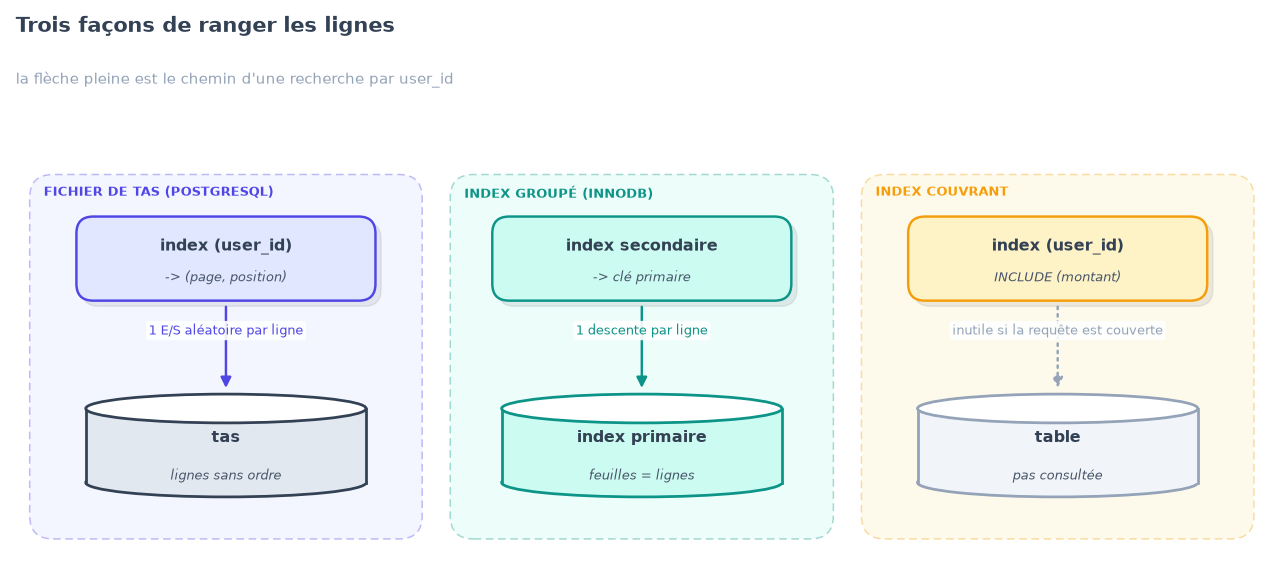

In [3]:
d = Diagram(13.5, 5.0, title="Trois façons de ranger les lignes",
            subtitle="la flèche pleine est le chemin d'une recherche par user_id")
d.group(0.2, 0.3, 4.4, 4.2, "fichier de tas (PostgreSQL)", color=INDIGO)
d.box("i1", 2.3, 3.3, "index (user_id)", sub="-> (page, position)", color=INDIGO, w=3.2)
d.box("h1", 2.3, 1.3, "tas", sub="lignes sans ordre", color=SLATE, kind="db", w=3.0, h=1.1)
d.arrow("i1", "h1", "1 E/S aléatoire par ligne", color=INDIGO)
d.group(4.7, 0.3, 8.8, 4.2, "index groupé (InnoDB)", color=TEAL)
d.box("i2", 6.75, 3.3, "index secondaire", sub="-> clé primaire", color=TEAL, w=3.2)
d.box("h2", 6.75, 1.3, "index primaire", sub="feuilles = lignes", color=TEAL, kind="db", w=3.0, h=1.1)
d.arrow("i2", "h2", "1 descente par ligne", color=TEAL)
d.group(9.1, 0.3, 13.3, 4.2, "index couvrant", color=AMBER)
d.box("i3", 11.2, 3.3, "index (user_id)", sub="INCLUDE (montant)", color=AMBER, w=3.2)
d.box("h3", 11.2, 1.3, "table", sub="pas consultée", color=GRAY, kind="db", w=3.0, h=1.1)
d.arrow("i3", "h3", "inutile si la requête est couverte", color=GRAY, style="dotted")
d.show()

**Quand l'index vaut-il mieux qu'un parcours complet ?** Modélisons une table d'un
million de lignes (50 lignes par page de tas, soit 20 000 pages) et une requête qui
sélectionne une fraction $s$ des lignes. Un parcours complet lit les 20 000 pages **en
séquence**. L'index secondaire lit quelques pages d'index puis, pour chaque ligne, une
page de tas **au hasard** : le nombre attendu de pages distinctes touchées par $m$
lignes vaut $P\,(1 - (1 - 1/P)^m)$. Un index groupé ou couvrant ne lit que les pages
contiguës qui contiennent les lignes voulues. On pondère une lecture séquentielle à 0,1
lecture aléatoire (ordre de grandeur sur SSD ; sur disque magnétique l'écart est bien
plus grand).

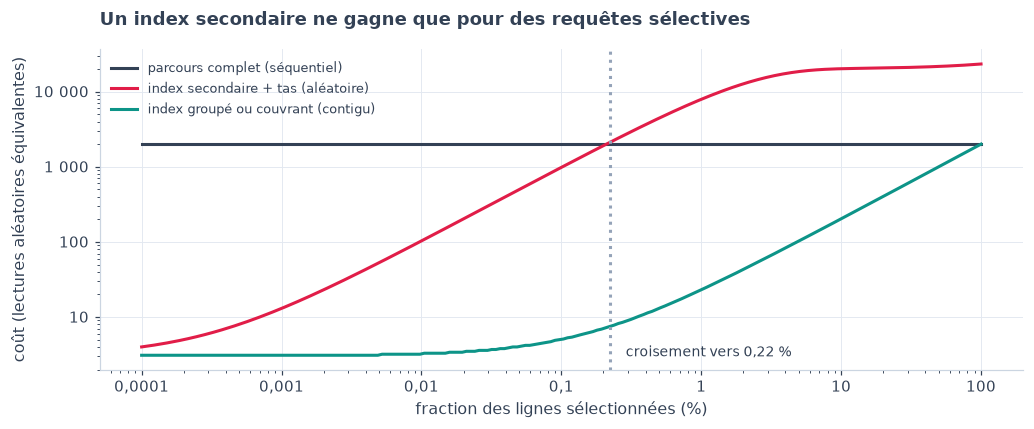

In [4]:
P, R, LEAF = 20_000, 50, 300
NR = P * R
s = np.logspace(-6, 0, 200)
m = s * NR
seq = 0.1
cout_scan = np.full_like(s, P * seq)
cout_tas = 3 + m / LEAF + P * (1 - (1 - 1 / P) ** m)
cout_groupe = 3 + np.ceil(m / R) * seq
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(s * 100, cout_scan, color=SLATE, label="parcours complet (séquentiel)")
ax.plot(s * 100, cout_tas, color=ROSE, label="index secondaire + tas (aléatoire)")
ax.plot(s * 100, cout_groupe, color=TEAL, label="index groupé ou couvrant (contigu)")
croise = s[np.argmax(cout_tas > cout_scan)] * 100
ax.axvline(croise, color=GRAY, ls=":")
ax.text(croise * 1.3, 3, f"croisement vers {croise:.2f} %".replace(".", ","), color=SLATE, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log"); S.plain_log_ticks(ax, "both")
ax.set_xlabel("fraction des lignes sélectionnées (%)"); ax.set_ylabel("coût (lectures aléatoires équivalentes)")
ax.set_title("Un index secondaire ne gagne que pour des requêtes sélectives")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Avec ce modèle, l'index secondaire sur un tas ne bat le parcours complet que si la
requête sélectionne **moins de quelques dixièmes de pourcent** des lignes. C'est
exactement le raisonnement de l'optimiseur de requêtes d'une base relationnelle, qui
préfère souvent un parcours séquentiel pour une requête peu sélective. L'index groupé
ou couvrant reste avantageux bien plus longtemps, car il lit des pages contiguës.

**Vérifions avec SQLite**, qui affiche son plan avec `EXPLAIN QUERY PLAN`. Une table
SQLite ordinaire est groupée sur un `rowid` caché ; on compare un index simple et un
index qui couvre la requête.

In [5]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE commandes (id INTEGER PRIMARY KEY, user_id INT, montant REAL, adresse TEXT)")
con.executemany("INSERT INTO commandes VALUES (?, ?, ?, ?)",
                [(int(r.id), int(r.user_id), float(r.montant), "x" * 200) for r in commandes.itertuples(index=False)])
requete = f"SELECT SUM(montant) FROM commandes WHERE user_id = {client}"


def plan(sql):
    return " | ".join(r[-1] for r in con.execute("EXPLAIN QUERY PLAN " + sql))


def chrono(sql, rep=200):
    t0 = time.perf_counter()
    for _ in range(rep):
        con.execute(sql).fetchall()
    return (time.perf_counter() - t0) / rep * 1e6


lignes = [dict(configuration="aucun index", plan=plan(requete), us_par_requete=chrono(requete, 20))]
con.execute("CREATE INDEX idx_user ON commandes(user_id)")
lignes.append(dict(configuration="index sur user_id", plan=plan(requete), us_par_requete=chrono(requete)))
con.execute("CREATE INDEX idx_user_couvrant ON commandes(user_id, montant)")
lignes.append(dict(configuration="index couvrant (user_id, montant)", plan=plan(requete),
                   us_par_requete=chrono(requete)))
pd.DataFrame(lignes)

,configuration,plan,us_par_requete
0,aucun index,SCAN commandes,941.920
1,index sur user_id,SEARCH commandes USING INDEX idx_user (user_id=?),320.074
2,"index couvrant (user_id, montant)",SEARCH commandes USING COVERING INDEX idx_user...,58.331


Sans index : `SCAN` (parcours complet). Avec l'index sur `user_id` : `SEARCH ... USING
INDEX`, puis une visite de la table par ligne trouvée. Avec l'index couvrant : `USING
COVERING INDEX`, la table n'est plus consultée et la requête est encore plus rapide.
(Les temps dépendent de la machine ; l'ordre de grandeur et le classement, eux, sont
stables.)

**Mises à jour dans un tas.** Si une ligne mise à jour ne grossit pas, on peut
l'écraser en place. Si elle grossit, il faut la déplacer : soit on met à jour **tous**
les index qui pointaient vers l'ancien emplacement, soit on laisse un **pointeur de
réacheminement** à l'ancienne place.

> **À retenir.** La valeur d'un index est soit la ligne (index groupé), soit une
> référence (clé primaire ou emplacement dans un tas), soit quelques colonnes (index
> couvrant). Les index secondaires sur tas ne paient que pour les requêtes sélectives.